Bai 1

=== 1. Hồi quy đơn giản ===
MSE: 14708.24 | R2: 0.9912


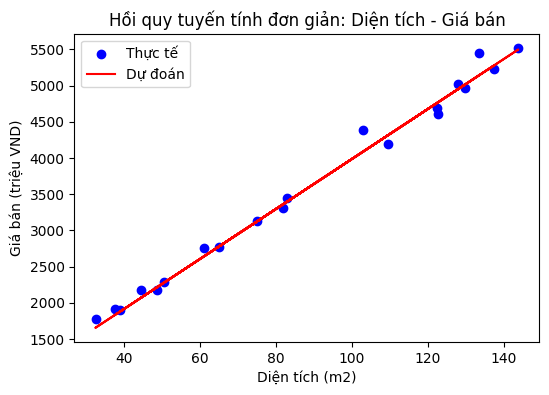


=== 2. Tăng dữ liệu (1000 mẫu) & tăng nhiễu ===
MSE: 214343.12 | R2: 0.8707

=== 3. Hồi quy đa biến ===
Hệ số (Diện tích, Phòng, Khoảng cách): [ 31.75018225 201.29881161 -24.56254116]
MSE: 31808.47 | R2: 0.9742


In [2]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_squared_error, r2_score

np.random.seed(42)
area = np.random.uniform(30, 150, (100, 1))
price = 500 + 35 * area + np.random.randn(100, 1) * 150

X_train, X_test, y_train, y_test = train_test_split(area, price, test_size=0.2, random_state=42)
model_1 = LinearRegression()
model_1.fit(X_train, y_train)
y_pred = model_1.predict(X_test)

print("=== 1. Hồi quy đơn giản ===")
print(f"MSE: {mean_squared_error(y_test, y_pred):.2f} | R2: {r2_score(y_test, y_pred):.4f}")

plt.figure(figsize=(6, 4))
plt.scatter(X_test, y_test, color="blue", label="Thực tế")
plt.plot(X_test, y_pred, color="red", label="Dự đoán")
plt.xlabel("Diện tích (m2)")
plt.ylabel("Giá bán (triệu VND)")
plt.title("Hồi quy tuyến tính đơn giản: Diện tích - Giá bán")
plt.legend()
plt.show()

np.random.seed(42)
area_big = np.random.uniform(30, 150, (1000, 1))
price_big = 500 + 35 * area_big + np.random.randn(1000, 1) * 500

X_tr2, X_te2, y_tr2, y_te2 = train_test_split(area_big, price_big, test_size=0.2, random_state=42)
model_2 = LinearRegression().fit(X_tr2, y_tr2)
pred_2 = model_2.predict(X_te2)
print("\n=== 2. Tăng dữ liệu (1000 mẫu) & tăng nhiễu ===")
print(f"MSE: {mean_squared_error(y_te2, pred_2):.2f} | R2: {r2_score(y_te2, pred_2):.4f}")


np.random.seed(42)
n = 300
dt = np.random.uniform(30, 150, n)
phong = np.random.randint(1, 6, n)
kc = np.random.uniform(1, 20, n)
gia = 400 + 32 * dt + 200 * phong - 25 * kc + np.random.randn(n) * 200

X_multi = np.column_stack([dt, phong, kc])
Xm_tr, Xm_te, ym_tr, ym_te = train_test_split(X_multi, gia, test_size=0.2, random_state=42)
model_3 = LinearRegression().fit(Xm_tr, ym_tr)
pred_3 = model_3.predict(Xm_te)

print("\n=== 3. Hồi quy đa biến ===")
print("Hệ số (Diện tích, Phòng, Khoảng cách):", model_3.coef_)
print(f"MSE: {mean_squared_error(ym_te, pred_3):.2f} | R2: {r2_score(ym_te, pred_3):.4f}")

Bai 2

Accuracy: 0.7833333333333333
Confusion Matrix:
 [[18  6]
 [ 7 29]]
Classification Report:
               precision    recall  f1-score   support

           0       0.72      0.75      0.73        24
           1       0.83      0.81      0.82        36

    accuracy                           0.78        60
   macro avg       0.77      0.78      0.78        60
weighted avg       0.79      0.78      0.78        60



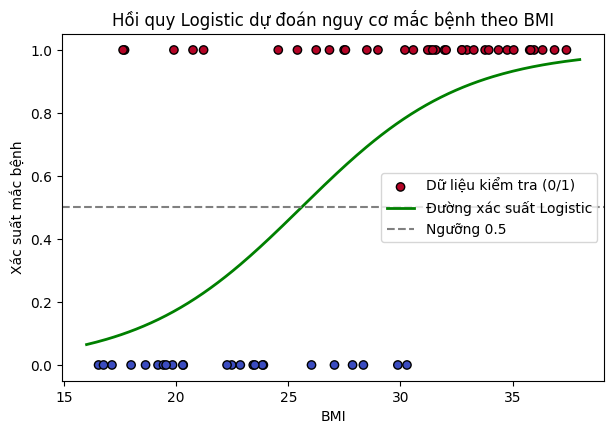

In [3]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report

np.random.seed(42)
bmi = np.random.uniform(16, 38, (300, 1))

logit = -6.5 + 0.26 * bmi
prob = 1 / (1 + np.exp(-logit))
disease = (np.random.rand(300, 1) < prob).astype(int).ravel()

X_train, X_test, y_train, y_test = train_test_split(bmi, disease, test_size=0.2, random_state=42)
clf = LogisticRegression()
clf.fit(X_train, y_train)

y_prob = clf.predict_proba(X_test)[:, 1]
y_pred = clf.predict(X_test)

print("Accuracy:", accuracy_score(y_test, y_pred))
print("Confusion Matrix:\n", confusion_matrix(y_test, y_pred))
print("Classification Report:\n", classification_report(y_test, y_pred))

bmi_grid = np.linspace(16, 38, 200).reshape(-1, 1)
prob_grid = clf.predict_proba(bmi_grid)[:, 1]

plt.figure(figsize=(7, 4.5))
plt.scatter(X_test, y_test, c=y_test, cmap="coolwarm", edgecolors="k", label="Dữ liệu kiểm tra (0/1)")
plt.plot(bmi_grid, prob_grid, color="green", linewidth=2, label="Đường xác suất Logistic")
plt.axhline(0.5, color="gray", linestyle="--", label="Ngưỡng 0.5")
plt.xlabel("BMI")
plt.ylabel("Xác suất mắc bệnh")
plt.title("Hồi quy Logistic dự đoán nguy cơ mắc bệnh theo BMI")
plt.legend()
plt.show()

Bai 3

Using Colab cache for faster access to the 'stroke-prediction-dataset' dataset.
Kích thước dữ liệu: (5110, 12)

Số lượng giá trị bị thiếu ở mỗi cột:
 id                     0
gender                 0
age                    0
hypertension           0
heart_disease          0
ever_married           0
work_type              0
Residence_type         0
avg_glucose_level      0
bmi                  201
smoking_status         0
stroke                 0
dtype: int64

Phân bố nhãn mục tiêu (stroke):
 stroke
0    95.127202
1     4.872798
Name: proportion, dtype: float64
KẾT QUẢ: Logistic Regression (Mặc định)
Accuracy : 0.9521
ROC-AUC  : 0.8387
Confusion Matrix:
 [[972   0]
 [ 49   1]]
Classification Report:
               precision    recall  f1-score   support

           0       0.95      1.00      0.98       972
           1       1.00      0.02      0.04        50

    accuracy                           0.95      1022
   macro avg       0.98      0.51      0.51      1022
weighted avg       

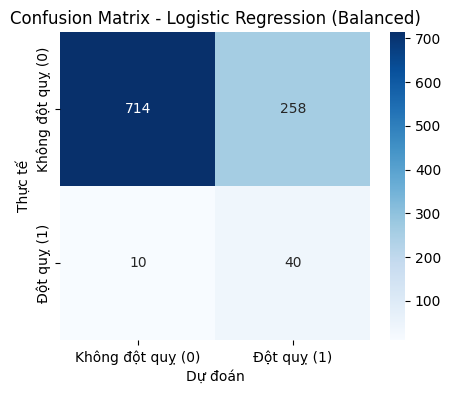

In [4]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report, roc_auc_score

# Load dataset
import kagglehub
import os
path = kagglehub.dataset_download("fedesoriano/stroke-prediction-dataset")
df = pd.read_csv(os.path.join(path, "healthcare-dataset-stroke-data.csv"))

print("Kích thước dữ liệu:", df.shape)
print("\nSố lượng giá trị bị thiếu ở mỗi cột:\n", df.isnull().sum())
print("\nPhân bố nhãn mục tiêu (stroke):\n", df['stroke'].value_counts(normalize=True) * 100)

# Tiền xử lí dữ liệu
df = df.drop(columns=['id'])
df = df[df['gender'] != 'Other']

X = df.drop(columns=['stroke'])
y = df['stroke']

num_cols = ['age', 'hypertension', 'heart_disease', 'avg_glucose_level', 'bmi']
cat_cols = ['gender', 'ever_married', 'work_type', 'Residence_type', 'smoking_status']

num_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler())
])

cat_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('onehot', OneHotEncoder(drop='first', handle_unknown='ignore'))
])

preprocessor = ColumnTransformer(
    transformers=[
        ('num', num_transformer, num_cols),
        ('cat', cat_transformer, cat_cols)
    ]
)

# Chia tập train/test
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

# Xây dựng, huấn luyện mô hình
model_default = Pipeline(steps=[
    ('prep', preprocessor),
    ('clf', LogisticRegression(max_iter=1000, random_state=42))
])

model_balanced = Pipeline(steps=[
    ('prep', preprocessor),
    ('clf', LogisticRegression(max_iter=1000, class_weight='balanced', random_state=42))
])

model_default.fit(X_train, y_train)
model_balanced.fit(X_train, y_train)

# Dự đoán đánh giá mô hình
for name, model in [("Logistic Regression (Mặc định)", model_default),
                    ("Logistic Regression (Balanced - Khuyên dùng)", model_balanced)]:
    y_pred = model.predict(X_test)
    y_prob = model.predict_proba(X_test)[:, 1]

    print("=" * 55)
    print(f"KẾT QUẢ: {name}")
    print(f"Accuracy : {accuracy_score(y_test, y_pred):.4f}")
    print(f"ROC-AUC  : {roc_auc_score(y_test, y_prob):.4f}")
    print("Confusion Matrix:\n", confusion_matrix(y_test, y_pred))
    print("Classification Report:\n", classification_report(y_test, y_pred, zero_division=0))

# Trực quan hóa ma trận nhầm lẫn
cm = confusion_matrix(y_test, model_balanced.predict(X_test))
plt.figure(figsize=(5, 4))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=['Không đột quỵ (0)', 'Đột quỵ (1)'],
            yticklabels=['Không đột quỵ (0)', 'Đột quỵ (1)'])
plt.xlabel('Dự đoán')
plt.ylabel('Thực tế')
plt.title('Confusion Matrix - Logistic Regression (Balanced)')
plt.show()

Bai tap ve nha

In [5]:
import numpy as np
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_squared_error, r2_score

np.random.seed(42)
X = np.random.uniform(0, 10, (200, 1))

for noise_std in [0.5, 1.5, 3.0, 6.0]:
    y = 2.5 + 4.0 * X + np.random.randn(200, 1) * noise_std
    X_tr, X_te, y_tr, y_te = train_test_split(X, y, test_size=0.2, random_state=42)
    m = LinearRegression().fit(X_tr, y_tr)
    pred = m.predict(X_te)
    print(f"Noise={noise_std:3.1f} | MSE={mean_squared_error(y_te, pred):6.2f} | R2={r2_score(y_te, pred):.4f}")

Noise=0.5 | MSE=  0.27 | R2=0.9980
Noise=1.5 | MSE=  2.49 | R2=0.9821
Noise=3.0 | MSE=  9.38 | R2=0.9456
Noise=6.0 | MSE= 29.92 | R2=0.7947


In [6]:
import numpy as np
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, precision_score, recall_score, confusion_matrix

np.random.seed(42)
X = np.random.normal(loc=25, scale=5, size=(300, 1))
prob_true = 1 / (1 + np.exp(-(-5 + 0.2 * X)))
y = (np.random.rand(300, 1) < prob_true).astype(int).ravel()

X_tr, X_te, y_tr, y_te = train_test_split(X, y, test_size=0.2, random_state=42)
model = LogisticRegression().fit(X_tr, y_tr)
probs = model.predict_proba(X_te)[:, 1]

for th in [0.3, 0.5, 0.6, 0.7]:
    y_pred_th = (probs >= th).astype(int)
    print(f"\n--- Ngưỡng (Threshold) = {th} ---")
    print(f"Accuracy: {accuracy_score(y_te, y_pred_th):.4f} | Precision: {precision_score(y_te, y_pred_th, zero_division=0):.4f} | Recall: {recall_score(y_te, y_pred_th, zero_division=0):.4f}")
    print("Confusion Matrix:\n", confusion_matrix(y_te, y_pred_th))


--- Ngưỡng (Threshold) = 0.3 ---
Accuracy: 0.5667 | Precision: 0.5370 | Recall: 0.9667
Confusion Matrix:
 [[ 5 25]
 [ 1 29]]

--- Ngưỡng (Threshold) = 0.5 ---
Accuracy: 0.5667 | Precision: 0.5588 | Recall: 0.6333
Confusion Matrix:
 [[15 15]
 [11 19]]

--- Ngưỡng (Threshold) = 0.6 ---
Accuracy: 0.6167 | Precision: 0.6842 | Recall: 0.4333
Confusion Matrix:
 [[24  6]
 [17 13]]

--- Ngưỡng (Threshold) = 0.7 ---
Accuracy: 0.5833 | Precision: 0.8571 | Recall: 0.2000
Confusion Matrix:
 [[29  1]
 [24  6]]


In [7]:
import numpy as np
import pandas as pd
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_squared_error, r2_score

url = "https://raw.githubusercontent.com/selva86/datasets/master/BostonHousing.csv"
try:
    df = pd.read_csv(url)
    target_col = "medv"
    X = df.drop(columns=[target_col])
    y = df[target_col]
    print("Đã tải thành công bộ dữ liệu Boston Housing, kích thước:", df.shape)
except Exception as e:
    print("Không tải được từ URL, dùng dữ liệu mô phỏng tương đương để chạy thử:", e)
    from sklearn.datasets import make_regression
    X, y = make_regression(n_samples=506, n_features=13, noise=4.5, random_state=42)

# Chia dữ liệu train/test (80/20)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# Huấn luyện mô hình Linear Regression
model = LinearRegression()
model.fit(X_train, y_train)

# Dự đoán và đánh giá
y_pred = model.predict(X_test)
mse = mean_squared_error(y_test, y_pred)
r2 = r2_score(y_test, y_pred)

print(f"Mean Squared Error (MSE): {mse:.4f}")
print(f"R^2 score: {r2:.4f}")

Đã tải thành công bộ dữ liệu Boston Housing, kích thước: (506, 14)
Mean Squared Error (MSE): 24.2911
R^2 score: 0.6688
